# 1. Limpieza y Unión de Datos

In [32]:
from google.colab import files

# Abre el explorador de archivos para cargar un documento
uploaded = files.upload()

for fn in uploaded.keys():
  print(f'Se cargó el archivo "{fn}" con una longitud de {len(uploaded[fn])} bytes')

Saving historico_equipos.csv to historico_equipos (1).csv
Saving X.csv to X (1).csv
Saving Y.csv to Y (1).csv
Saving Z.csv to Z (1).csv
Se cargó el archivo "historico_equipos (1).csv" con una longitud de 159264 bytes
Se cargó el archivo "X (1).csv" con una longitud de 164774 bytes
Se cargó el archivo "Y (1).csv" con una longitud de 73199 bytes
Se cargó el archivo "Z (1).csv" con una longitud de 69831 bytes


Dataframe historicos_equipos

In [33]:
import pandas as pd

df_historico = pd.read_csv('historico_equipos.csv')
df_historico['Date'] = pd.to_datetime(df_historico['Date'])
df_historico.head()

,Date,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
0,2010-01-04,80.12,527.5,2225.25,434.73,931.73
1,2010-01-05,80.59,527.5,2246.50,449.97,968.56
2,2010-01-06,81.89,527.5,2302.50,444.48,960.51
3,2010-01-07,81.51,527.5,2306.50,440.90,960.14
4,2010-01-08,81.37,552.5,2261.25,448.82,949.55


In [34]:
print(df_historico.shape)
print(df_historico.dtypes)
print(df_historico.describe())

(3530, 6)
Date             datetime64[ns]
Price_X                 float64
Price_Y                 float64
Price_Z                 float64
Price_Equipo1           float64
Price_Equipo2           float64
dtype: object
                                Date      Price_X      Price_Y      Price_Z  \
count                           3530  3530.000000  3530.000000  3530.000000   
mean   2016-10-31 13:29:20.226629120    78.091014   555.527108  2037.432073   
min              2010-01-04 00:00:00    19.330000   257.500000  1421.500000   
25%              2013-06-03 06:00:00    57.052500   482.500000  1767.250000   
50%              2016-10-31 12:00:00    75.400000   541.625000  1974.750000   
75%              2020-04-01 18:00:00   104.582500   620.000000  2235.937500   
max              2023-08-31 00:00:00   127.980000  1062.370000  3984.000000   
std                              NaN    25.186945   138.489003   373.140448   

       Price_Equipo1  Price_Equipo2  
count    3530.000000    3530.00000

Dataframe_x

In [35]:
df_x = pd.read_csv('X.csv')
df_x['Date'] = pd.to_datetime(df_x['Date'])
df_x.head()

,Date,Price
0,2024-04-04,89.18
1,2024-04-03,89.35
2,2024-04-02,88.92
3,2024-04-01,87.42
4,2024-03-28,87.48


In [36]:
print(df_x.shape)
print(df_x.dtypes)
print(df_x.describe())

(9144, 2)
Date     datetime64[ns]
Price           float64
dtype: object
                                Date        Price
count                           9144  9144.000000
mean   2006-06-20 12:57:00.472441088    51.323922
min              1988-06-27 00:00:00     9.640000
25%              1997-07-10 18:00:00    19.687500
50%              2006-07-24 12:00:00    45.940000
75%              2015-06-01 06:00:00    75.207500
max              2024-04-04 00:00:00   146.080000
std                              NaN    32.994964


Dataframe_z

In [37]:
df_z = pd.read_csv('Z.csv')
df_z['Date'] = pd.to_datetime(df_z['Date'])
df_z = df_z[['Date', 'Price']]
df_z.head()

,Date,Price
0,2010-01-01,2225.25
1,2010-01-04,2225.25
2,2010-01-05,2246.50
3,2010-01-06,2302.50
4,2010-01-07,2306.50


In [38]:
print(df_z.shape)
print(df_z.dtypes)
print(df_z.describe())

(3565, 2)
Date     datetime64[ns]
Price           float64
dtype: object
                                Date        Price
count                           3565  3565.000000
mean   2016-10-31 14:23:59.999999744  2037.081197
min              2010-01-01 00:00:00  1421.500000
25%              2013-06-03 00:00:00  1767.500000
50%              2016-11-01 00:00:00  1974.750000
75%              2020-04-01 00:00:00  2235.750000
max              2023-08-31 00:00:00  3984.000000
std                              NaN   372.976076


Dataframe_y

In [39]:
df_y = pd.read_csv('Y.csv', sep=';', decimal=',')
df_y['Date'] = pd.to_datetime(df_y['Date'], format='%d/%m/%Y')
df_y.head()

,Date,Price
0,2023-09-12,547.33
1,2023-09-11,546.00
2,2023-09-08,545.00
3,2023-09-07,550.00
4,2023-09-06,552.50


In [40]:
print(df_y.shape)
print(df_y.dtypes)
print(df_y.describe())

(4485, 2)
Date     datetime64[ns]
Price           float64
dtype: object
                                Date        Price
count                           4485  4485.000000
mean   2015-02-08 13:59:55.183946496   565.458283
min              2006-07-11 00:00:00   257.500000
25%              2010-10-26 00:00:00   485.000000
50%              2015-02-09 00:00:00   543.670000
75%              2019-05-27 00:00:00   617.670000
max              2023-09-12 00:00:00  1062.370000
std                              NaN   145.150530


Análisis de coincidencia

In [41]:
fechas_hist = set(df_historico['Date'])
fechas_x = set(df_x['Date'])
fechas_y = set(df_y['Date'])
fechas_z = set(df_z['Date'])
comunes = fechas_hist & fechas_x & fechas_y & fechas_z
print(len(comunes))

3530


In [42]:
precios_hist = set(df_historico['Price_X'])
precios_x = set(df_x['Price'])

comunes = precios_hist & precios_x
print("Histórico únicos:", len(precios_hist))
print("X únicos:", len(precios_x))
print("Comunes exactos:", len(comunes))
print()

precios_histy = set(df_historico['Price_Y'])
precios_y = set(df_y['Price'])

comunesy = precios_histy & precios_y
print("Histórico únicos:", len(precios_histy))
print("Y únicos:", len(precios_y))
print("Comunes exactos:", len(comunesy))
print()

precios_histz = set(df_historico['Price_Z'])
precios_z = set(df_z['Price'])

comunesz = precios_histz & precios_z
print("Histórico únicos:", len(precios_histz))
print("Z únicos:", len(precios_z))
print("Comunes exactos:", len(comunesz))
print()

Histórico únicos: 2837
X únicos: 5454
Comunes exactos: 2837

Histórico únicos: 1219
Y únicos: 1237
Comunes exactos: 1219

Histórico únicos: 2321
Z únicos: 2321
Comunes exactos: 2321



In [43]:
for nombre, df_nuevo, col in [
    ('X', df_x, 'Price_X'),
    ('Y', df_y, 'Price_Y'),
    ('Z', df_z, 'Price_Z'),
]:
    pares_hist = set(zip(df_historico['Date'], df_historico[col]))
    pares_nuevo = set(zip(df_nuevo['Date'], df_nuevo.rename(columns={'Price': col})[col]))

    comunes = pares_hist & pares_nuevo
    print(f"{nombre}: {len(comunes)} / {len(pares_hist)} pares (fecha, precio) en común")

X: 3530 / 3530 pares (fecha, precio) en común
Y: 3530 / 3530 pares (fecha, precio) en común
Z: 3530 / 3530 pares (fecha, precio) en común


Unión de Datos

In [44]:
df_x = df_x.sort_values('Date').reset_index(drop=True)
df_y = df_y.sort_values('Date').reset_index(drop=True)
df_z = df_z.sort_values('Date').reset_index(drop=True)

df_l = (df_x. merge(df_y, on='Date', how='outer'). merge(df_z, on='Date', how='outer'))
df_l.sort_values('Date').reset_index(drop=True)

print(df_l.head())

        Date  Price_x  Price_y  Price
0 1988-06-27    15.10      NaN    NaN
1 1988-06-28    15.27      NaN    NaN
2 1988-06-29    15.47      NaN    NaN
3 1988-06-30    14.85      NaN    NaN
4 1988-07-01    14.60      NaN    NaN


# 2. Análisis de Relación y Regresión Lineal

In [45]:
df_historico = df_historico.sort_values('Date').reset_index(drop=True)

In [46]:
cor = df_historico [['Price_X', 'Price_Y', 'Price_Z', 'Price_Equipo1', 'Price_Equipo2']].corr()

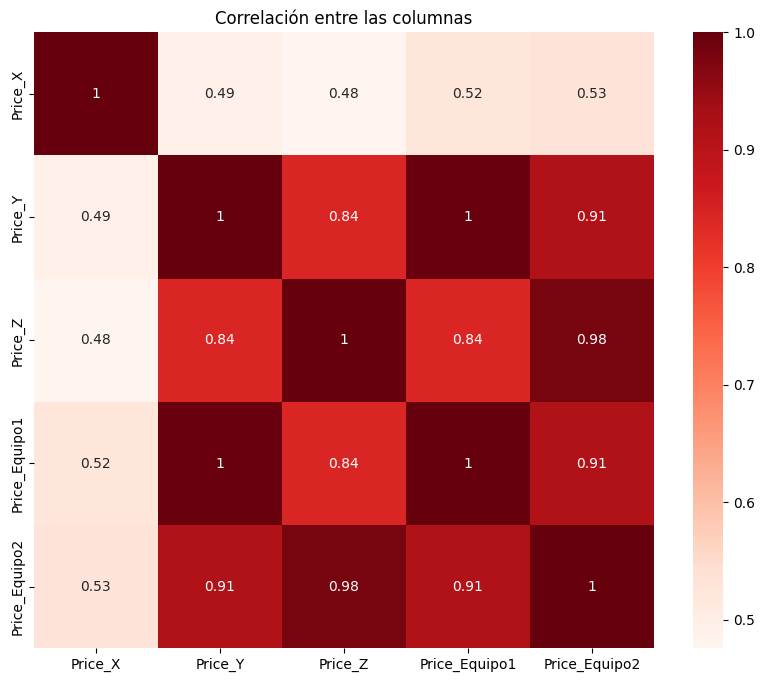

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(cor, annot=True, cmap=plt.cm.Reds)
plt.title('Correlación entre las columnas')
plt.show()

Relación entre el Equipo 1 y el precio de Y

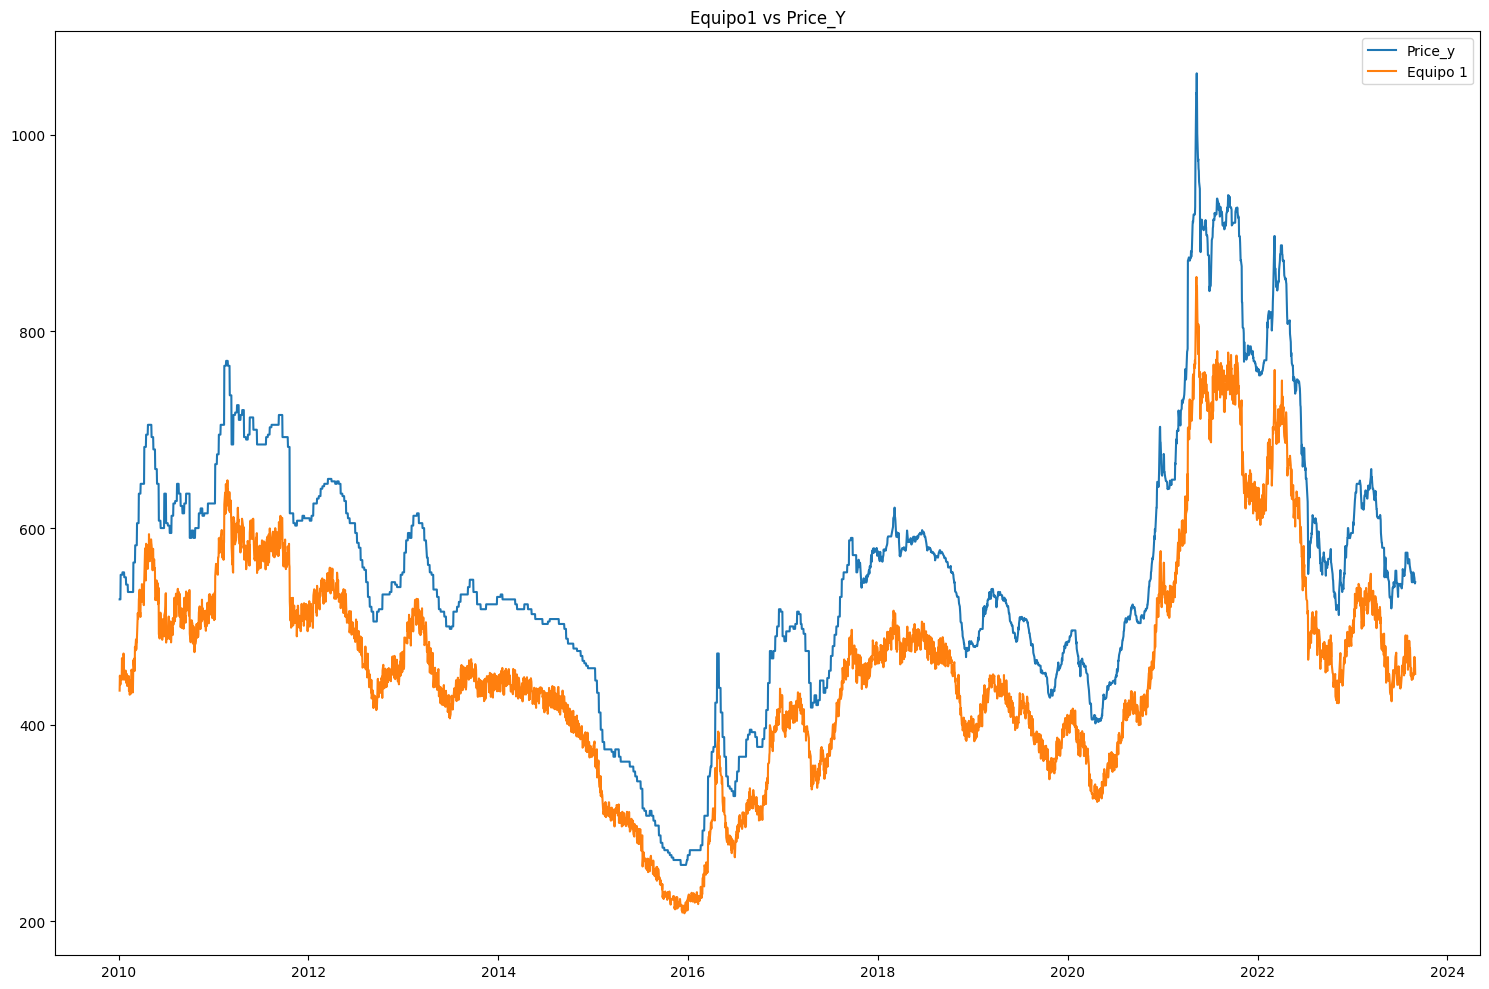

In [48]:
fig, axes = plt.subplots(1, 1, figsize=(15, 10))

axes.plot(df_historico['Date'], df_historico['Price_Y'], label='Price_y')
axes.plot(df_historico['Date'], df_historico['Price_Equipo1'], label= 'Equipo 1')
axes.legend(); axes.set_title('Equipo1 vs Price_Y')

plt.tight_layout()
plt.show()

Relación entre el Equipo 2 y el precio de Z

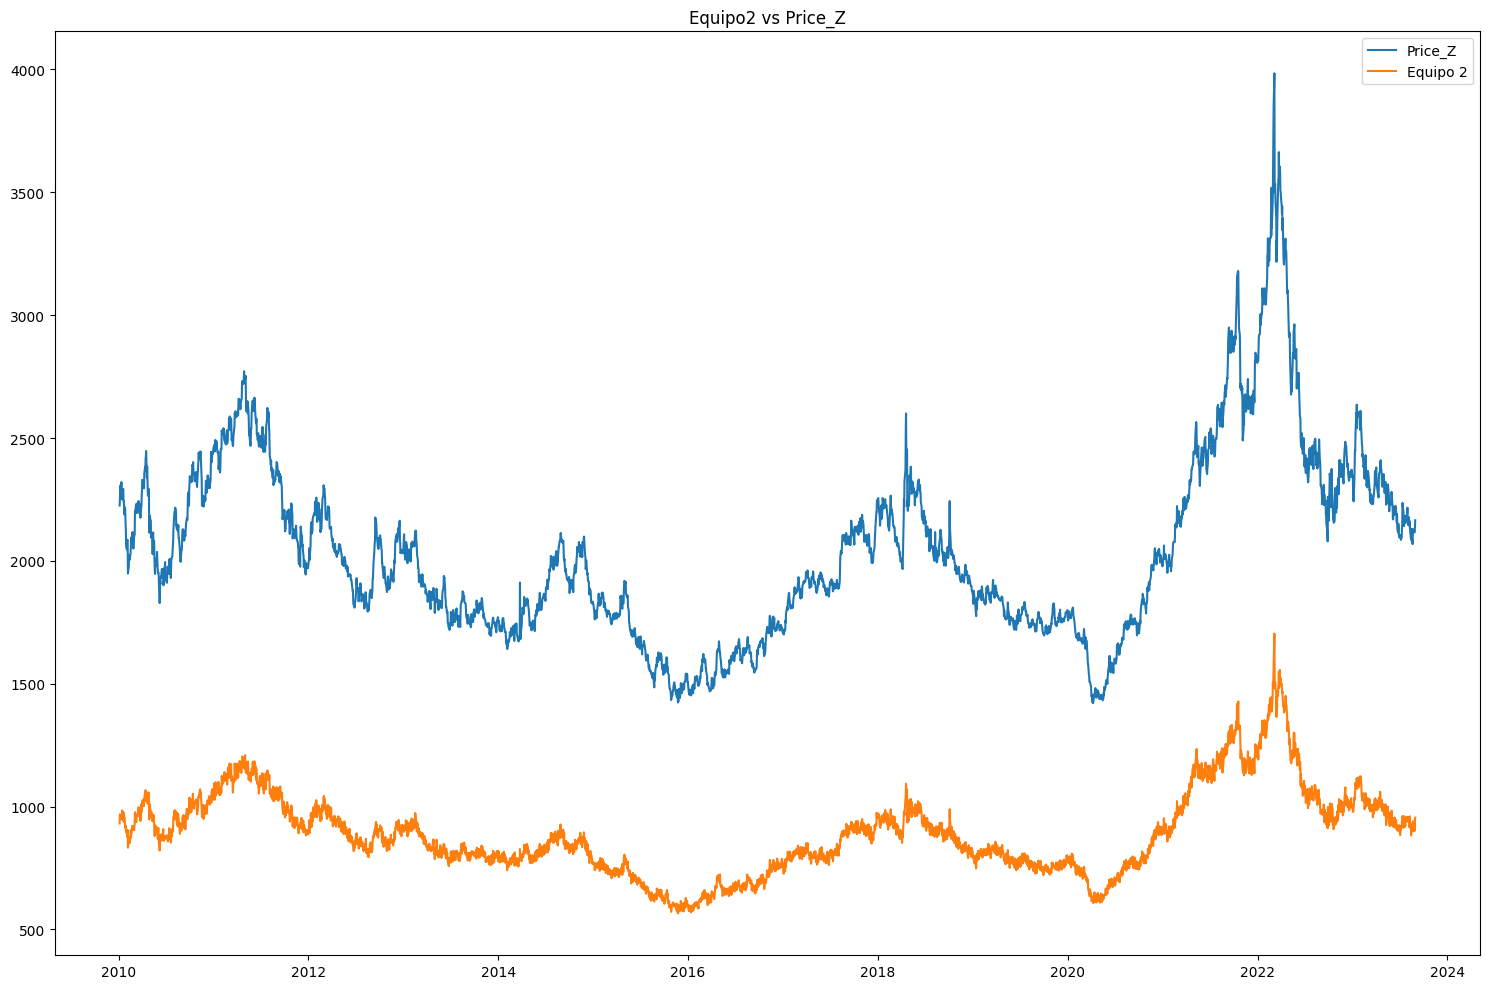

In [49]:
fig, axes = plt.subplots(1, 1, figsize=(15, 10))

axes.plot(df_historico['Date'], df_historico['Price_Z'], label='Price_Z')
axes.plot(df_historico['Date'], df_historico['Price_Equipo2'], label= 'Equipo 2')
axes.legend(); axes.set_title('Equipo2 vs Price_Z')

plt.tight_layout()
plt.show()

Coeficientes del modelo de regresión lineal

In [50]:
import numpy as np

a, b = np.polyfit(df_historico['Price_Y'], df_historico['Price_Equipo1'], 1)
pred1 = a * df_historico['Price_Y'] + b

print("Equipo1 = %.4f * Price_Y + %.4f" % (a, b))


Equipo1 = 0.8181 * Price_Y + 5.5646


In [51]:
a2, b2 = np.polyfit(df_historico['Price_Z'], df_historico['Price_Equipo2'], 1)
pred2 = a2 * df_historico['Price_Z'] + b2

print("Equipo2 = %.4f * Price_Z + %.4f" % (a2, b2))

Equipo2 = 0.4478 * Price_Z + -22.4056


Evaluación del error

In [52]:
from sklearn.metrics import r2_score
r2_eq1 = r2_score(df_historico['Price_Equipo1'], pred1)
r2_eq2 = r2_score(df_historico['Price_Equipo2'], pred2)
print("R^2 Equipo1:", r2_eq1)
print("R^2 Equipo2:", r2_eq2)

R^2 Equipo1: 0.993246508001213
R^2 Equipo2: 0.9656497759055902


Predictor ambiguo

In [53]:
import statsmodels.api as sm
x = sm.add_constant(df_historico[['Price_X']])
model = sm.OLS(df_historico['Price_Equipo1'], x).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          Price_Equipo1   R-squared:                       0.274
Model:                            OLS   Adj. R-squared:                  0.274
Method:                 Least Squares   F-statistic:                     1331.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):          1.54e-247
Time:                        21:07:33   Log-Likelihood:                -21152.
No. Observations:                3530   AIC:                         4.231e+04
Df Residuals:                    3528   BIC:                         4.232e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        275.5675      5.313     51.868      0.0

# 3. Proyección con Prophet

Análisis estacionario

In [54]:
from statsmodels.tsa.stattools import adfuller

serie_y = df_l['Price_y'].dropna()

resultado = adfuller(serie_y)
p_value = resultado[1]


print(f"P-value de la prueba: {p_value:.4f}")

if p_value < 0.05:
    print("Resultado: La serie es ESTACIONARIA.")
else:
    print("Resultado: La serie NO es estacionaria.")

P-value de la prueba: 0.0126
Resultado: La serie es ESTACIONARIA.


/tmp/ipykernel_1588/1414154846.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado = adfuller(serie_y)


In [55]:
from statsmodels.tsa.stattools import adfuller


serie_z = df_l['Price'].dropna()


resultado_z = adfuller(serie_z)
p_value_z = resultado_z[1]


print(f"P-value de Z: {p_value_z:.4f}")

if p_value_z < 0.05:
    print("Resultado: La serie Z es ESTACIONARIA.")
else:
    print("Resultado: La serie Z NO es estacionaria.")

P-value de Z: 0.1841
Resultado: La serie Z NO es estacionaria.


/tmp/ipykernel_1588/4046348329.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_z = adfuller(serie_z)


Pronostico en price 'y' y price 'z' evaluados con los coeficientes del modelo de Regresión

In [56]:
from prophet import Prophet
import pandas as pd
import statsmodels.api as sm

# 1. PREDECIR Y Y CALCULAR EQUIPO 1
# Preparamos los datos de Y desde el dataframe de materias (df_l)
df_y_prophet = df_l[['Date', 'Price_y']].dropna().rename(columns={'Date': 'ds', 'Price_y': 'y'})

# Entrenamos Prophet para Y
m_y = Prophet(interval_width=0.95) # 95% de confianza
m_y.fit(df_y_prophet)

# Predecimos hacia el futuro
futuro_y = m_y.make_future_dataframe(periods=180)
forecast_y = m_y.predict(futuro_y)

# Filtramos solo las fechas futuras
futuro_real_y = forecast_y[forecast_y['ds'] > df_y_prophet['ds'].max()].copy()

# Aplicamos la FÓRMULA del Equipo1 (usando los valores que ya calculamos antes)
# Equipo1 = 0.8181 * Y + 5.5646
futuro_real_y['Equipo1_Esperado'] = 0.8181 * futuro_real_y['yhat'] + 5.5646
futuro_real_y['Equipo1_Minimo']   = 0.8181 * futuro_real_y['yhat_lower'] + 5.5646
futuro_real_y['Equipo1_Maximo']   = 0.8181 * futuro_real_y['yhat_upper'] + 5.5646


# 2. PREDECIR Z Y CALCULAR EQUIPO 2
# Preparamos los datos de Z desde el dataframe de materias (df_l)
df_z_prophet = df_l[['Date', 'Price']].dropna().rename(columns={'Date': 'ds', 'Price': 'y'})

# Entrenamos Prophet para Z
m_z = Prophet(interval_width=0.95)
m_z.fit(df_z_prophet)

# Predecimos hacia el futuro
futuro_z = m_z.make_future_dataframe(periods=180)
forecast_z = m_z.predict(futuro_z)

# Filtramos solo las fechas futuras
futuro_real_z = forecast_z[forecast_z['ds'] > df_z_prophet['ds'].max()].copy()

# Aplicamos la FÓRMULA del Equipo2
# Equipo2 = 0.4478 * Z - 22.4056
futuro_real_z['Equipo2_Esperado'] = 0.4478 * futuro_real_z['yhat'] - 22.4056
futuro_real_z['Equipo2_Minimo']   = 0.4478 * futuro_real_z['yhat_lower'] - 22.4056
futuro_real_z['Equipo2_Maximo']   = 0.4478 * futuro_real_z['yhat_upper'] - 22.4056


# 3. UNIR LOS RESULTADOS EN UNA SOLA TABLA
tabla_final = pd.DataFrame({'Fecha': futuro_real_y['ds'].values})
tabla_final['Equipo1_Esperado'] = futuro_real_y['Equipo1_Esperado'].values
tabla_final['Equipo1_Minimo'] = futuro_real_y['Equipo1_Minimo'].values
tabla_final['Equipo1_Maximo'] = futuro_real_y['Equipo1_Maximo'].values
tabla_final['Equipo2_Esperado'] = futuro_real_z['Equipo2_Esperado'].values
tabla_final['Equipo2_Minimo'] = futuro_real_z['Equipo2_Minimo'].values
tabla_final['Equipo2_Maximo'] = futuro_real_z['Equipo2_Maximo'].values

print(tabla_final.head())

INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


       Fecha  Equipo1_Esperado  Equipo1_Minimo  Equipo1_Maximo  \
0 2023-09-13        594.001857      447.162648      748.253492   
1 2023-09-14        594.180409      450.000742      746.249496   
2 2023-09-15        594.267533      430.526520      744.952111   
3 2023-09-16        569.046601      415.211224      716.378538   
4 2023-09-17        651.793769      497.359578      791.729325   

   Equipo2_Esperado  Equipo2_Minimo  Equipo2_Maximo  
0       1100.857907      928.756014     1257.262688  
1       1147.106126      971.272837     1310.949422  
2       1147.825490      985.625600     1321.543829  
3       1101.755196      929.872676     1261.521491  
4       1102.128873      932.880418     1273.731705  


Visualización del pronóstico de 'Price_y' y la visualización de tendencias en distintas capas de tiempo.

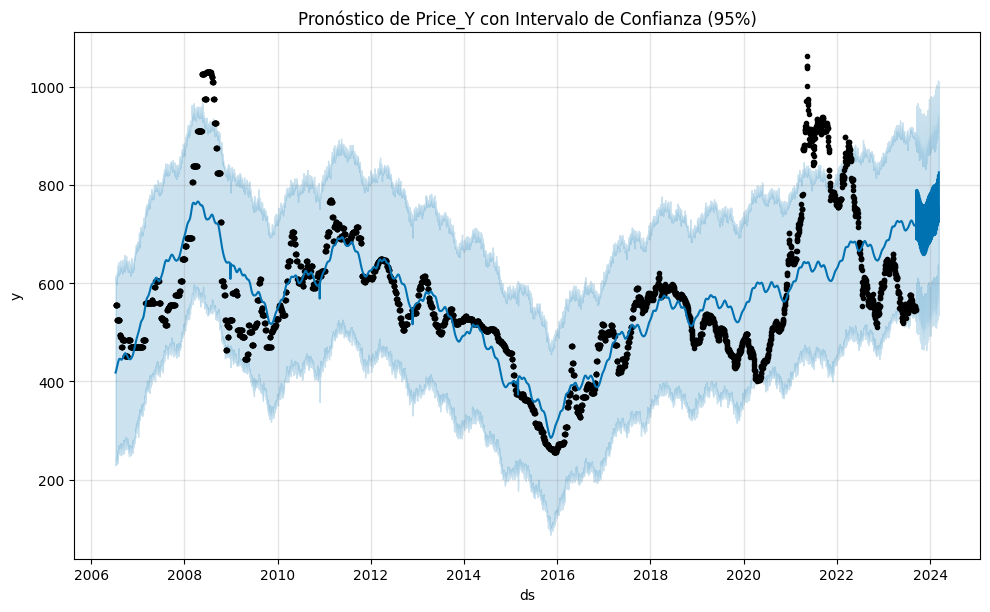

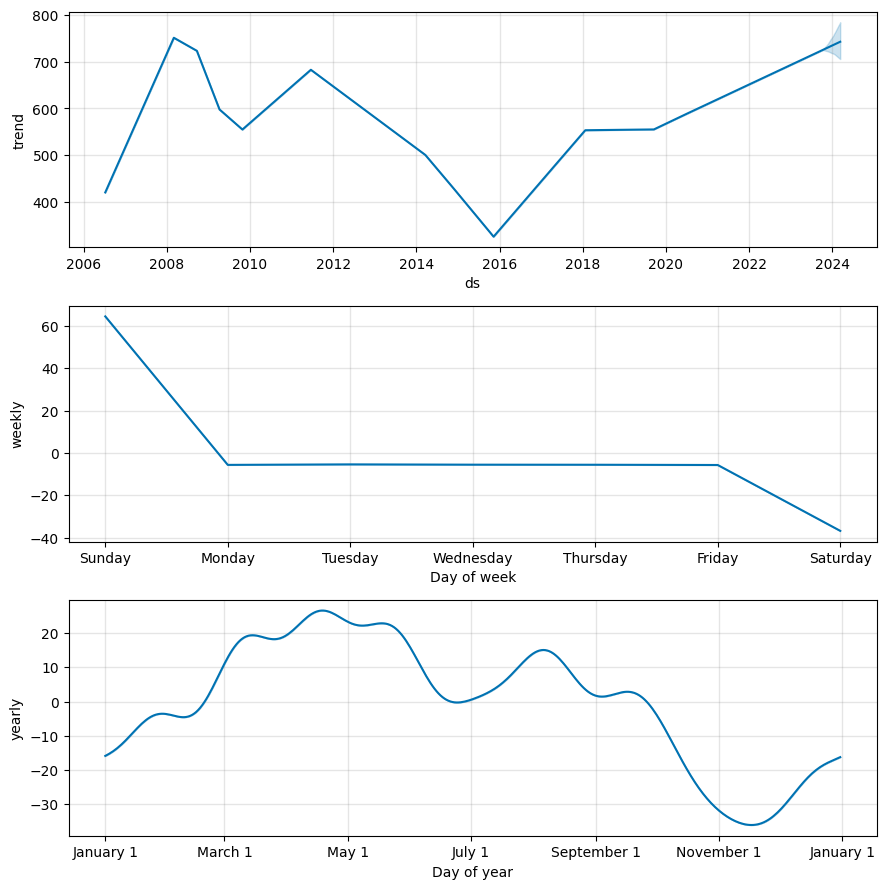

In [57]:
from prophet.plot import plot_plotly, plot_components
import matplotlib.pyplot as plt

fig1 = m_y.plot(forecast_y)
plt.title('Pronóstico de Price_Y con Intervalo de Confianza (95%)')
plt.show()

fig2 = m_y.plot_components(forecast_y)
plt.show()

Visualización del pronóstico de Price_z y la visualización de tendencias en distintas capas de tiempo.

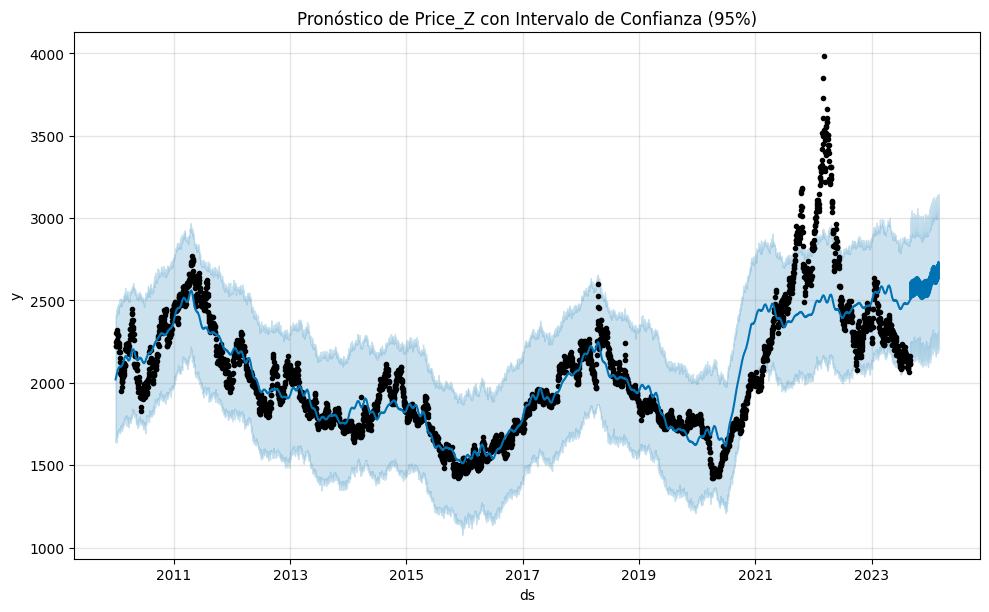

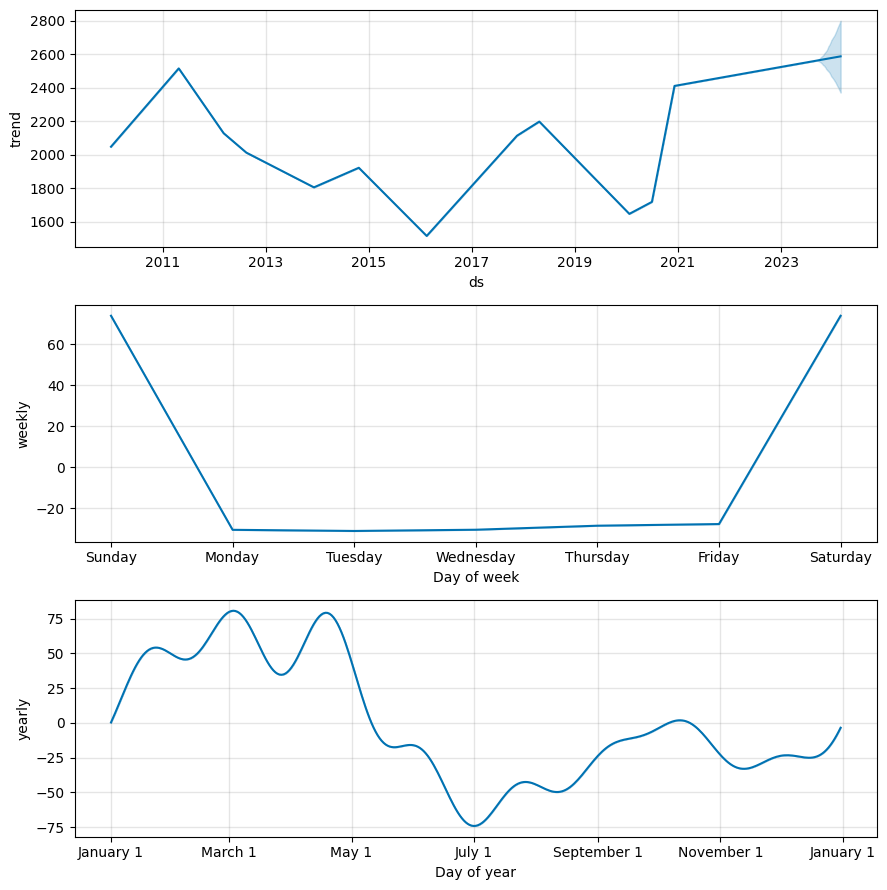

In [58]:
from prophet.plot import plot_plotly, plot_components
import matplotlib.pyplot as plt

fig1 = m_z.plot(forecast_z)
plt.title('Pronóstico de Price_Z con Intervalo de Confianza (95%)')
plt.show()

fig2 = m_z.plot_components(forecast_z)
plt.show()

Visualización de la Proyección del Precio del Equipo1

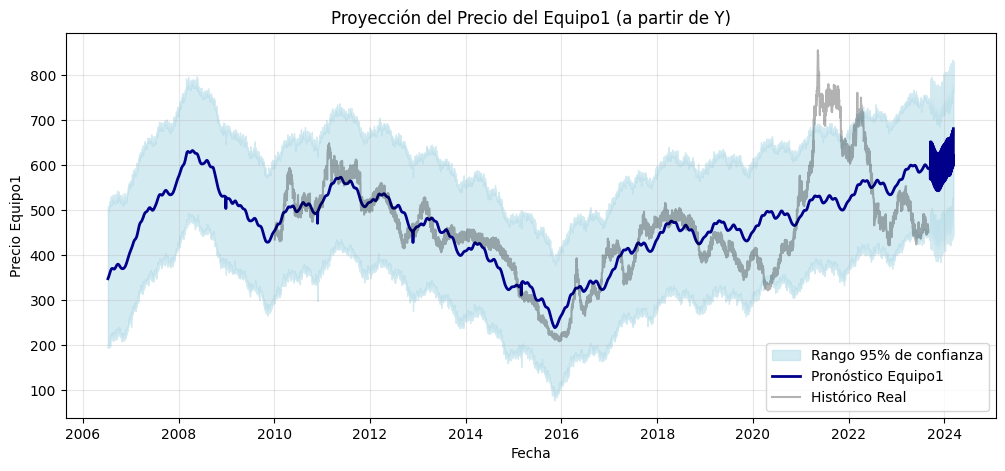

In [59]:
import matplotlib.pyplot as plt

equipo1_pred = forecast_y.copy()

equipo1_pred['equipo1_esperado'] = 0.8181 * equipo1_pred['yhat'] + 5.5646
equipo1_pred['equipo1_min'] = 0.8181 * equipo1_pred['yhat_lower'] + 5.5646
equipo1_pred['equipo1_max'] = 0.8181 * equipo1_pred['yhat_upper'] + 5.5646

plt.figure(figsize=(12, 5))

plt.fill_between(equipo1_pred['ds'],
                 equipo1_pred['equipo1_min'],
                 equipo1_pred['equipo1_max'],
                 color='lightblue', alpha=0.5, label='Rango 95% de confianza')

plt.plot(equipo1_pred['ds'], equipo1_pred['equipo1_esperado'],
         color='darkblue', linewidth=2, label='Pronóstico Equipo1')

plt.plot(df_historico['Date'], df_historico['Price_Equipo1'],
         color='black', alpha=0.3, label='Histórico Real')

plt.title('Proyección del Precio del Equipo1 (a partir de Y)')
plt.xlabel('Fecha')
plt.ylabel('Precio Equipo1')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Visualización de la Proyección del Precio del Equipo2

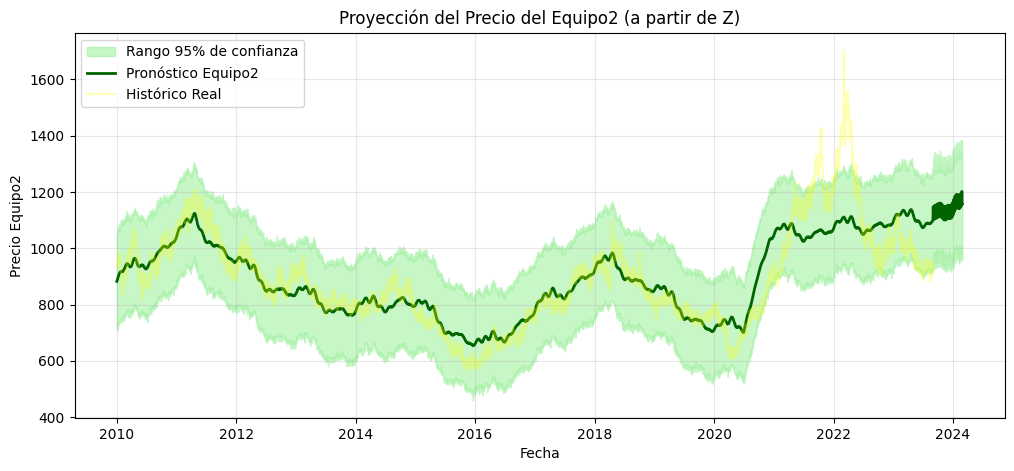

In [60]:
import matplotlib.pyplot as plt

equipo2_pred = forecast_z.copy()

equipo2_pred['equipo2_esperado'] = 0.4478 * equipo2_pred['yhat'] - 22.4056
equipo2_pred['equipo2_min'] = 0.4478 * equipo2_pred['yhat_lower'] - 22.4056
equipo2_pred['equipo2_max'] = 0.4478 * equipo2_pred['yhat_upper'] - 22.4056

plt.figure(figsize=(12, 5))

plt.fill_between(equipo2_pred['ds'],
                 equipo2_pred['equipo2_min'],
                 equipo2_pred['equipo2_max'],
                 color='lightgreen', alpha=0.5, label='Rango 95% de confianza')

plt.plot(equipo2_pred['ds'], equipo2_pred['equipo2_esperado'],
         color='darkgreen', linewidth=2, label='Pronóstico Equipo2')

plt.plot(df_historico['Date'], df_historico['Price_Equipo2'],
         color='yellow', alpha=0.3, label='Histórico Real')

plt.title('Proyección del Precio del Equipo2 (a partir de Z)')
plt.xlabel('Fecha')
plt.ylabel('Precio Equipo2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 4. Agente de IA (Chatbot con Herramientas y Memoria)

In [61]:
!pip install gradio -q

import gradio as gr
import pandas as pd
import re

# CONOCIMIENTO EXTERNO (Noticias del sector)
NOTICIAS_MERCADO = """
[Reporte de Inteligencia de Mercado y Análisis Prophet]

Tendencia Histórica (Largo Plazo):
- La materia prima Y (Equipo1) sufrió una caída crítica en 2016, pero su tendencia post-pandemia (2021-2024) es firmemente alcista.
- La materia prima Z (Equipo2) mantiene una tendencia estable con picos de volatilidad.

Estacionalidad Anual (Mejor época de compra):
- Se detectó un patrón claro en el ciclo anual: los precios suelen tocar su punto máximo en primavera (marzo y abril).
- El mejor momento para adquirir los equipos es en otoño/invierno (octubre y noviembre), donde los precios históricamente caen a su nivel más bajo del año.

Análisis Semanal (Comportamiento por día):
- El modelo detectó que el mercado laboral (martes a viernes) mantiene precios estables y planos.

"""

# MEMORIA DEL AGENTE
memoria = {"ultimo_equipo": None}

# PREDICCIÓN (Futuro)
def consultar_prediccion(equipo, fecha_str):
    try:
        fecha = pd.to_datetime(fecha_str)
        if "1" in equipo:
            memoria["ultimo_equipo"] = "Equipo1"
            fila = equipo1_pred.iloc[(equipo1_pred['ds'] - fecha).abs().argsort()[:1]]
            valor = fila['equipo1_esperado'].values[0]
            return f"[Futuro] Para {fecha_str[:10]}, el Equipo1 costará ${valor:,.2f}."
        elif "2" in equipo:
            memoria["ultimo_equipo"] = "Equipo2"
            fila = equipo2_pred.iloc[(equipo2_pred['ds'] - fecha).abs().argsort()[:1]]
            valor = fila['equipo2_esperado'].values[0]
            return f"[Futuro] Para {fecha_str[:10]}, el Equipo2 costará ${valor:,.2f}."
    except Exception:
        return "No encontré esa fecha. Usa el formato AAAA-MM-DD."

# HISTÓRICO (Pasado)
def consultar_historico(equipo, fecha_str):
    try:
        fecha = pd.to_datetime(fecha_str)
        fila = df_historico.iloc[(df_historico['Date'] - fecha).abs().argsort()[:1]]

        if "1" in equipo:
            memoria["ultimo_equipo"] = "Equipo1"
            valor = fila['Price_Equipo1'].values[0]
            return f"[Pasado] El {fila['Date'].values[0].astype('datetime64[D]')}, el Equipo1 costó ${valor:,.2f}."
        elif "2" in equipo:
            memoria["ultimo_equipo"] = "Equipo2"
            valor = fila['Price_Equipo2'].values[0]
            return f"[Pasado] El {fila['Date'].values[0].astype('datetime64[D]')}, el Equipo2 costó ${valor:,.2f}."
    except Exception:
        return "No encontré ese dato histórico."

# EL CEREBRO DEL AGENTE
def agente_responder(mensaje, historial):
    msg = mensaje.lower()

    # REGLA 1: MEMORIA (Debe ir primero para que no se confunda con la palabra "equipo")
    if "anterior" in msg or "ultimo" in msg or "último" in msg or "y el otro" in msg:
        if memoria["ultimo_equipo"]:
            return f"Recordando: el último equipo que consultamos fue el {memoria['ultimo_equipo']}."
        else:
            return "Aún no hemos consultado ningún equipo."

    # REGLA 2: NOTICIAS (Debe ir antes que precios para que no choque con la palabra "mercado")
    elif "noticia" in msg or "mercado" in msg or "contexto" in msg:
        return NOTICIAS_MERCADO

    # REGLA 3: PRECIOS (Futuro o Pasado)
    elif "equipo" in msg or "cuesta" in msg or "precio" in msg:
        fecha_match = re.search(r'\d{4}-\d{2}-\d{2}', mensaje)

        if fecha_match:
            fecha = fecha_match.group()

            if "equipo1" in msg or "equipo 1" in msg:
                equipo = "1"
            elif "equipo2" in msg or "equipo 2" in msg:
                equipo = "2"
            else:
                equipo = "1"

            palabras_pasado = ["pasado", "historico", "histórico", "anterior", "2010", "2011", "2012", "2013", "2014", "2015", "2016", "2017", "2018", "2019", "2020", "2021", "2022", "2023"]

            if any(palabra in msg for palabra in palabras_pasado) or int(fecha[:4]) < 2024:
                return consultar_historico(equipo, fecha)
            else:
                return consultar_prediccion(equipo, fecha)
        else:
            return "Entendido. Para qué fecha exacta? (Usa el formato AAAA-MM-DD, ej: 2024-05-15)"

    # REGLA 4: Último recurso (Fallos controlados)
    else:
        return "Hola. Soy tu Agente de Costos. Puedo predecir costos futuros (ej. 'Precio del Equipo2 el 2024-04-01') o darte noticias del mercado (ej. 'Dame noticias')."

# INTERFAZ GRÁFICA DEL CHAT (Gradio)
def chat(mensaje, historial):
    respuesta = agente_responder(mensaje, historial)
    historial.append({"role": "user", "content": mensaje})
    historial.append({"role": "assistant", "content": respuesta})
    return historial, ""

with gr.Blocks(title="Agente de IA") as demo:
    gr.Markdown("# Agente de IA - Gestión de Costos")
    gr.Markdown("Pregúntame por los costos futuros de los equipos o pídeme noticias del mercado.")

    chatbot = gr.Chatbot(height=400)
    msg = gr.Textbox(label="Escribe tu pregunta aquí y presiona Enter...")
    clear = gr.Button("Limpiar chat")

    msg.submit(chat, [msg, chatbot], [chatbot, msg])
    clear.click(lambda: None, None, chatbot, queue=False)

demo.launch(debug=True)

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://425e53874ead21c90f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://425e53874ead21c90f.gradio.live
